## **PROYECTO FINAL ANALISIS MULTIVARIADO**
Juan Esteban Romero Castillo

In [2]:
# Celda de código: imports y semilla
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

#### **Comprensión del contexto y de los datos**


## 1. Contexto del problema
Una entidad bancaria quiere anticipar qué clientes de tarjeta de crédito están en riesgo
de abandonar el servicio (churn). Retener a un cliente suele costar menos que captar uno
nuevo, por lo que identificar la fuga a tiempo permite diseñar acciones de retención.

## 2. Unidad de análisis
Cada registro representa a un cliente de la entidad con su perfil demográfico,
su relación con el banco, su comportamiento transaccional y sus saldos y límites de crédito.

## 3. Propósito del análisis
Construir un modelo de **clasificación binaria** que prediga si un cliente abandona
(variable objetivo) a partir de sus características financieras y de comportamiento.

## 4. Fuente
Base de datos asignada: n.º 13, Abandono de Clientes de Tarjetas de Crédito (Churn).

#### **Carga y exploración**

Que se tiene dentro de data

In [3]:
from pathlib import Path

# Ajusta el nombre del archivo a como lo tengas en la carpeta data
RUTA_DATA = Path("data")
print("Archivos en data/:", [p.name for p in RUTA_DATA.iterdir()])

Archivos en data/: ['BankChurners.csv']


Dimension y carga de la bd

In [4]:
ARCHIVO = "BankChurners.csv"
df = pd.read_csv(RUTA_DATA / ARCHIVO)

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (10127, 21)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000


Estructura general

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  str    
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  str    
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           10127 non-null  str    
 6   Marital_Status            10127 non-null  str    
 7   Income_Category           10127 non-null  str    
 8   Card_Category             10127 non-null  str    
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_Revolving_B

tipos de datos y valores únicos por columna

In [6]:
resumen = pd.DataFrame({
    "tipo": df.dtypes,
    "n_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "%_nulos": (df.isna().mean() * 100).round(2),
})
resumen

,tipo,n_unicos,nulos,%_nulos
CLIENTNUM,int64,10127,0,0.000
Attrition_Flag,str,2,0,0.000
Customer_Age,int64,45,0,0.000
Gender,str,2,0,0.000
Dependent_count,int64,6,0,0.000
Education_Level,str,7,0,0.000
Marital_Status,str,4,0,0.000
Income_Category,str,6,0,0.000
Card_Category,str,4,0,0.000
Months_on_book,int64,44,0,0.000


Estadísticas descriptivas

In [7]:
display(df.describe().T)                      # numéricas
display(df.describe(include="object").T)      # categóricas

,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,"10,127.000","739,177,606.334","36,903,783.450","708,082,083.000","713,036,770.500","717,926,358.000","773,143,533.000","828,343,083.000"
Customer_Age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000
Dependent_count,"10,127.000",2.346,1.299,0.000,1.000,2.000,3.000,5.000
Months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000
Total_Relationship_Count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000
Months_Inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000
Contacts_Count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000
Credit_Limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000"
Total_Revolving_Bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000"
Avg_Open_To_Buy,"10,127.000","7,469.140","9,090.685",3.000,"1,324.500","3,474.000","9,859.000","34,516.000"


,count,unique,top,freq
Attrition_Flag,10127,2,Existing Customer,8500
Gender,10127,2,F,5358
Education_Level,10127,7,Graduate,3128
Marital_Status,10127,4,Married,4687
Income_Category,10127,6,Less than $40K,3561
Card_Category,10127,4,Blue,9436


identificar la variable objetivo y su distribución

In [8]:
print(df.columns.tolist())

['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


Variable objetivo

<ArrowStringArray>
['Existing Customer', 'Attrited Customer']
Length: 2, dtype: str
                   conteo      %
Attrition_Flag                  
Existing Customer    8500 83.930
Attrited Customer    1627 16.070


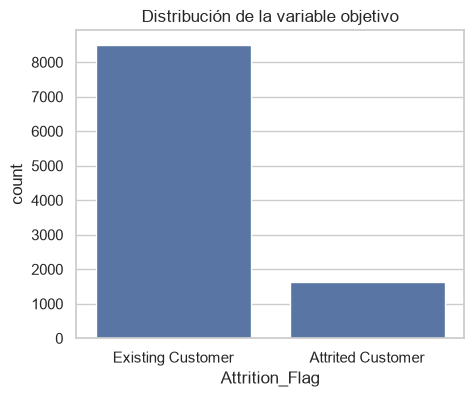

In [9]:
TARGET = "Attrition_Flag"

print(df[TARGET].unique())

conteo = df[TARGET].value_counts()
porcentaje = (df[TARGET].value_counts(normalize=True) * 100).round(2)
print(pd.concat([conteo, porcentaje], axis=1, keys=["conteo", "%"]))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Distribución de la variable objetivo")
plt.show()

Distribucion de variables numericas

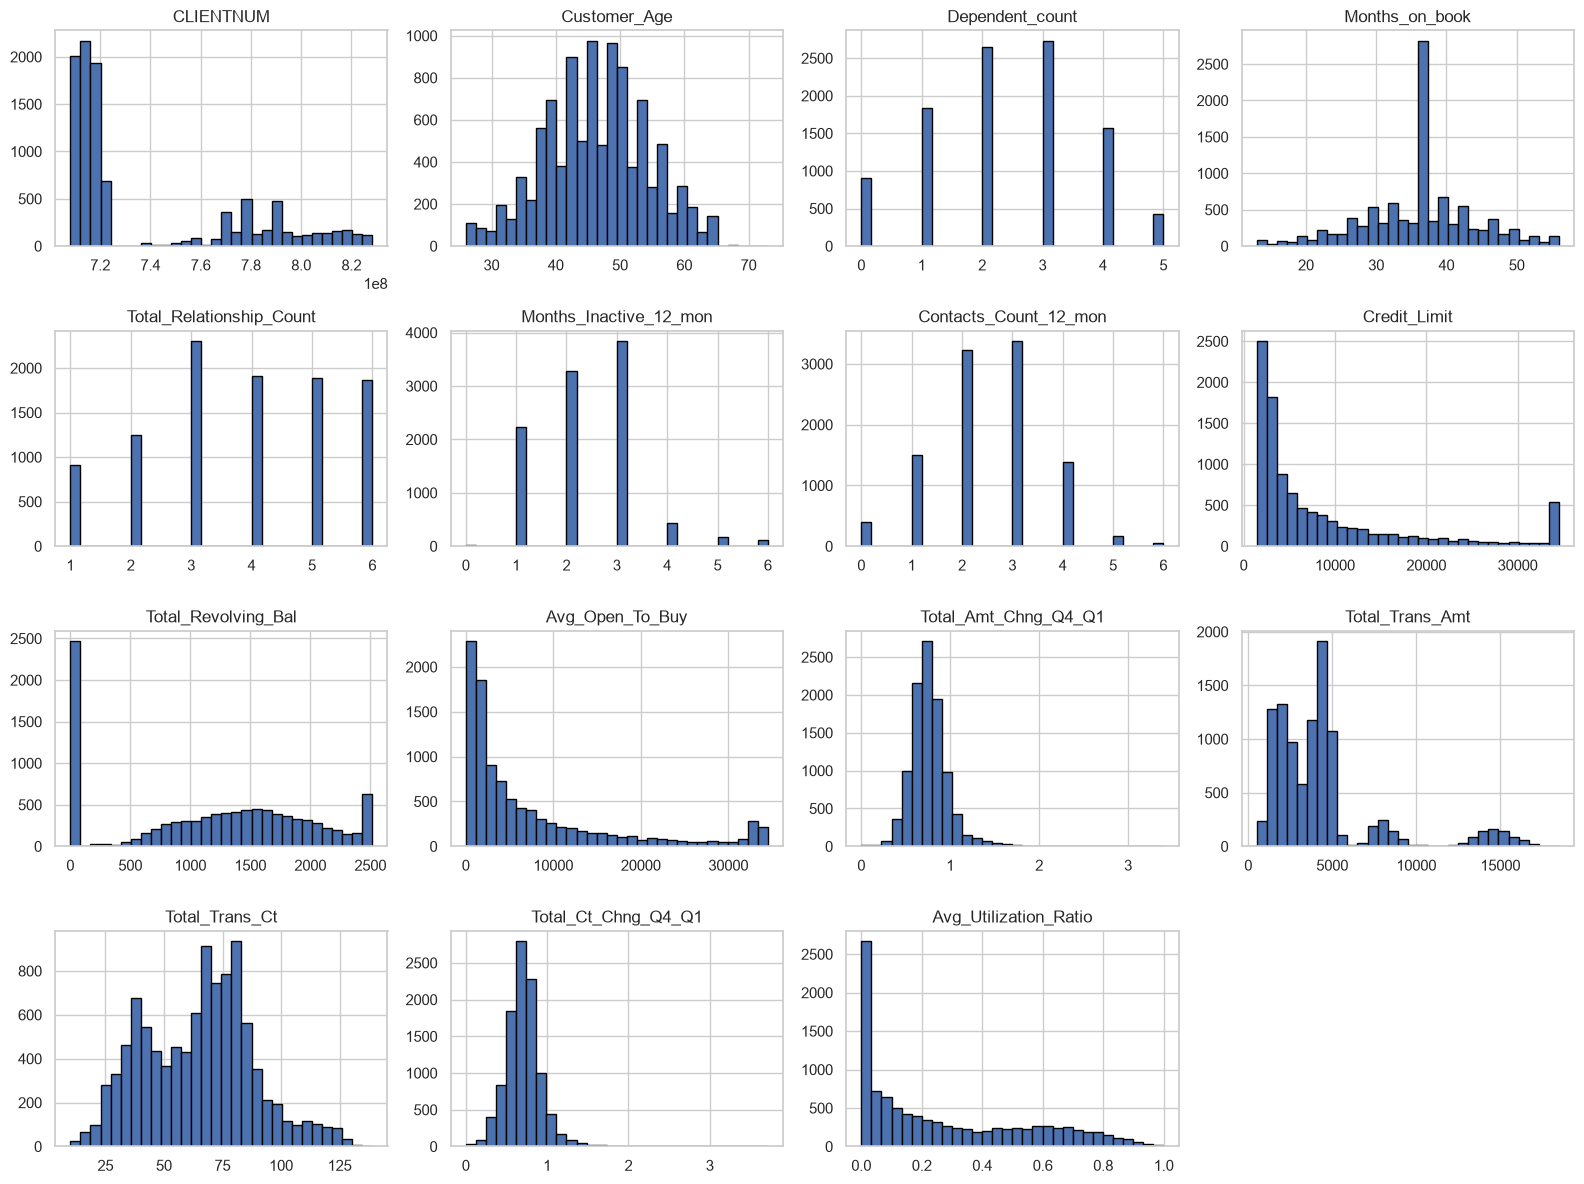

In [10]:
num_cols = df.select_dtypes(include="number").columns.tolist()

df[num_cols].hist(bins=30, figsize=(16, 12), edgecolor="black")
plt.tight_layout()
plt.show()

distribución de variables categóricas

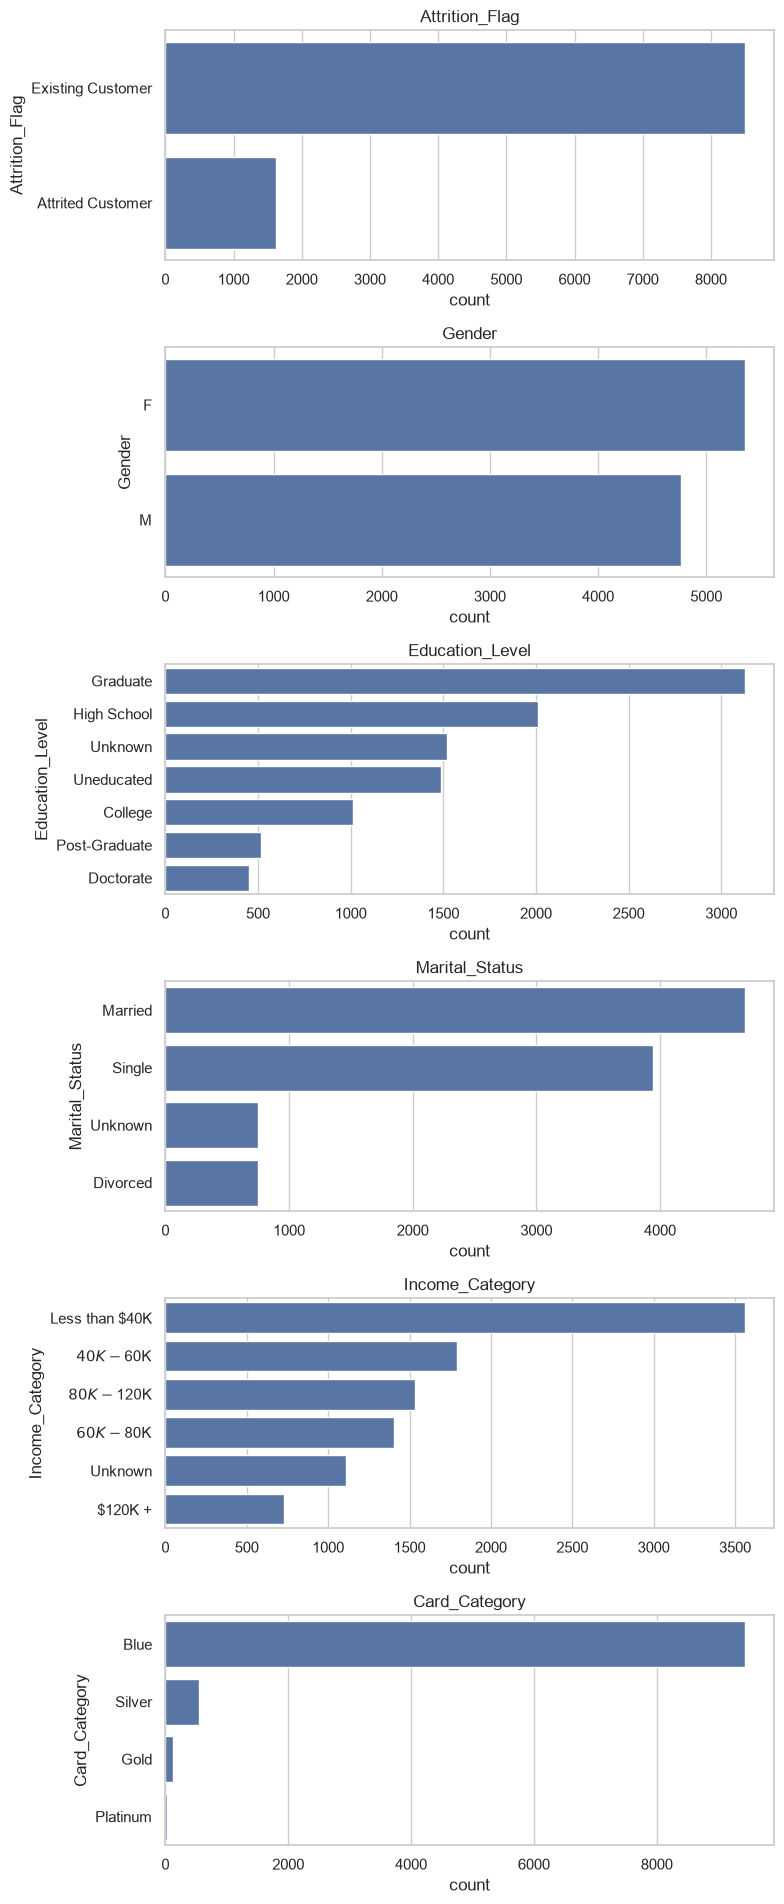

In [11]:
cat_cols = df.select_dtypes(include="object").columns.tolist()

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(8, 3.2 * len(cat_cols)))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, y=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Creacion o codificacion de variable objetivo - 0 No abandona - 1 Abandona

In [12]:
df["churn"] = (df[TARGET] == "Attrited Customer").astype(int)

print(df[[TARGET, "churn"]].value_counts())

Attrition_Flag     churn
Existing Customer  0        8500
Attrited Customer  1        1627
Name: count, dtype: int64


In [13]:
dif = (df["Credit_Limit"] - df["Total_Revolving_Bal"] - df["Avg_Open_To_Buy"]).abs()
print("Máx. diferencia:", dif.max())

Máx. diferencia: 5.684341886080802e-14


Hallazgos 5.2 
- 10.127 registros y 21 columnas, sin valores nulos en ninguna.
- Objetivo desbalanceado: 8.500 clientes existentes (83,93 %) contra 1.627 que abandonaron (16,07 %). Esto condiciona las métricas y la validación.
- Avg_Open_To_Buy es exactamente Credit_Limit - Total_Revolving_Bal (la diferencia es de 1e-14, solo ruido de punto flotante), así que es redundante.
- Education_Level, Marital_Status e Income_Category traen una categoría Unknown que hay que tratar.

## Diccionario de datos

| Variable | Tipo | Descripción |
|---|---|---|
| CLIENTNUM | Identificador | Código único del cliente (se excluye del modelo) |
| Attrition_Flag | Categórica (objetivo) | Si el cliente sigue (Existing) o abandonó (Attrited) |
| Customer_Age | Numérica | Edad del cliente en años |
| Gender | Categórica | Género (M/F) |
| Dependent_count | Numérica | Número de personas a cargo |
| Education_Level | Categórica | Nivel educativo |
| Marital_Status | Categórica | Estado civil |
| Income_Category | Categórica ordinal | Rango de ingreso anual |
| Card_Category | Categórica ordinal | Tipo de tarjeta (Blue, Silver, Gold, Platinum) |
| Months_on_book | Numérica | Meses de antigüedad con el banco |
| Total_Relationship_Count | Numérica | Total de productos que el cliente tiene con el banco |
| Months_Inactive_12_mon | Numérica | Meses de inactividad en los últimos 12 |
| Contacts_Count_12_mon | Numérica | Contactos con el banco en los últimos 12 meses |
| Credit_Limit | Numérica | Límite de crédito de la tarjeta |
| Total_Revolving_Bal | Numérica | Saldo rotativo total |
| Avg_Open_To_Buy | Numérica | Crédito disponible (límite − saldo rotativo) |
| Total_Amt_Chng_Q4_Q1 | Numérica | Cambio en el monto transaccionado (Q4 vs Q1) |
| Total_Trans_Amt | Numérica | Monto total transaccionado en los últimos 12 meses |
| Total_Trans_Ct | Numérica | Número total de transacciones en los últimos 12 meses |
| Total_Ct_Chng_Q4_Q1 | Numérica | Cambio en el número de transacciones (Q4 vs Q1) |
| Avg_Utilization_Ratio | Numérica | Proporción del límite de crédito que se está usando |

#### **5.3 Calidad y preparación**

faltantes y duplicados

In [14]:
print("Nulos totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("CLIENTNUM duplicados:", df["CLIENTNUM"].duplicated().sum())

Nulos totales: 0
Filas duplicadas: 0
CLIENTNUM duplicados: 0


inconsistencias, categoría Unknown y categorías

In [15]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("Attrition_Flag").tolist()

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())

print("\n% de 'Unknown' por columna:")
unk = {c: round((df[c] == "Unknown").mean() * 100, 2) for c in cat_cols}
print(pd.Series(unk)[lambda s: s > 0])


--- Gender ---
Gender
F    5358
M    4769
Name: count, dtype: int64

--- Education_Level ---
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

--- Marital_Status ---
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

--- Income_Category ---
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

--- Card_Category ---
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

% de 'Unknown' por columna:
Education_Level   15.000
Marital_Status     7.400
Income_Category   10.980
dtype: float64


tasa de abandono por categoría (sirve para decidir qué hacer con Unknown)

In [16]:
for col in ["Education_Level", "Marital_Status", "Income_Category", "Card_Category", "Gender"]:
    print(f"\n{col}")
    print((df.groupby(col)["churn"].agg(["count", "mean"])
             .rename(columns={"mean": "tasa_abandono"}).round(3)))


Education_Level
                 count  tasa_abandono
Education_Level                      
College           1013          0.152
Doctorate          451          0.211
Graduate          3128          0.156
High School       2013          0.152
Post-Graduate      516          0.178
Uneducated        1487          0.159
Unknown           1519          0.169

Marital_Status
                count  tasa_abandono
Marital_Status                      
Divorced          748          0.162
Married          4687          0.151
Single           3943          0.169
Unknown           749          0.172

Income_Category
                 count  tasa_abandono
Income_Category                      
$120K +            727          0.173
$40K - $60K       1790          0.151
$60K - $80K       1402          0.135
$80K - $120K      1535          0.158
Less than $40K    3561          0.172
Unknown           1112          0.168

Card_Category
               count  tasa_abandono
Card_Category                  

coherencia de variables derivadas

In [17]:
# Utilización = saldo rotativo / límite
util_calc = df["Total_Revolving_Bal"] / df["Credit_Limit"]
print("Máx. diferencia con Avg_Utilization_Ratio:", (util_calc - df["Avg_Utilization_Ratio"]).abs().max())

# Rangos lógicos
print("Edad mín/máx:", df["Customer_Age"].min(), df["Customer_Age"].max())
print("Antigüedad > edad adulta?:", (df["Months_on_book"] / 12 > df["Customer_Age"] - 16).sum())

Máx. diferencia con Avg_Utilization_Ratio: 0.0005000000000000004
Edad mín/máx: 26 73
Antigüedad > edad adulta?: 0


valores atípicos (método IQR)

,n_outliers,%
Credit_Limit,984,9.720
Avg_Open_To_Buy,963,9.510
Total_Trans_Amt,896,8.850
Contacts_Count_12_mon,629,6.210
Total_Amt_Chng_Q4_Q1,396,3.910
Total_Ct_Chng_Q4_Q1,394,3.890
Months_on_book,386,3.810
Months_Inactive_12_mon,331,3.270
Customer_Age,2,0.020
Total_Trans_Ct,2,0.020


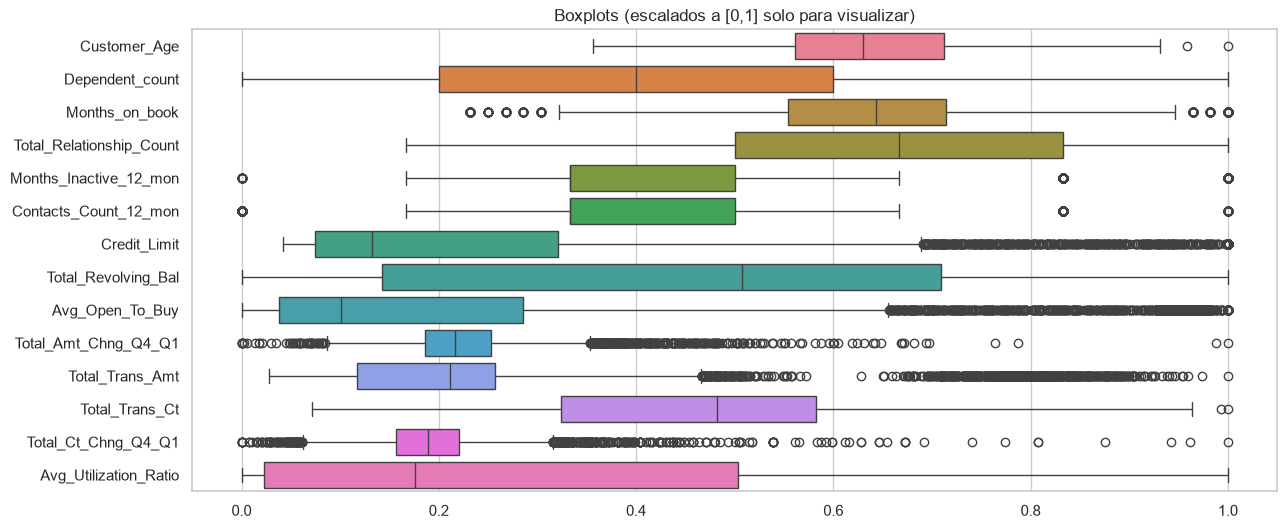

In [18]:
num_cols = df.select_dtypes(include="number").columns.drop(["CLIENTNUM", "churn"]).tolist()

def resumen_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "n_outliers": [resumen_outliers(df[c]) for c in num_cols],
}, index=num_cols)
out["%"] = (out["n_outliers"] / len(df) * 100).round(2)
display(out.sort_values("%", ascending=False))

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[num_cols] / df[num_cols].max(), orient="h")
plt.title("Boxplots (escalados a [0,1] solo para visualizar)")
plt.show()

correlaciones y multicolinealidad

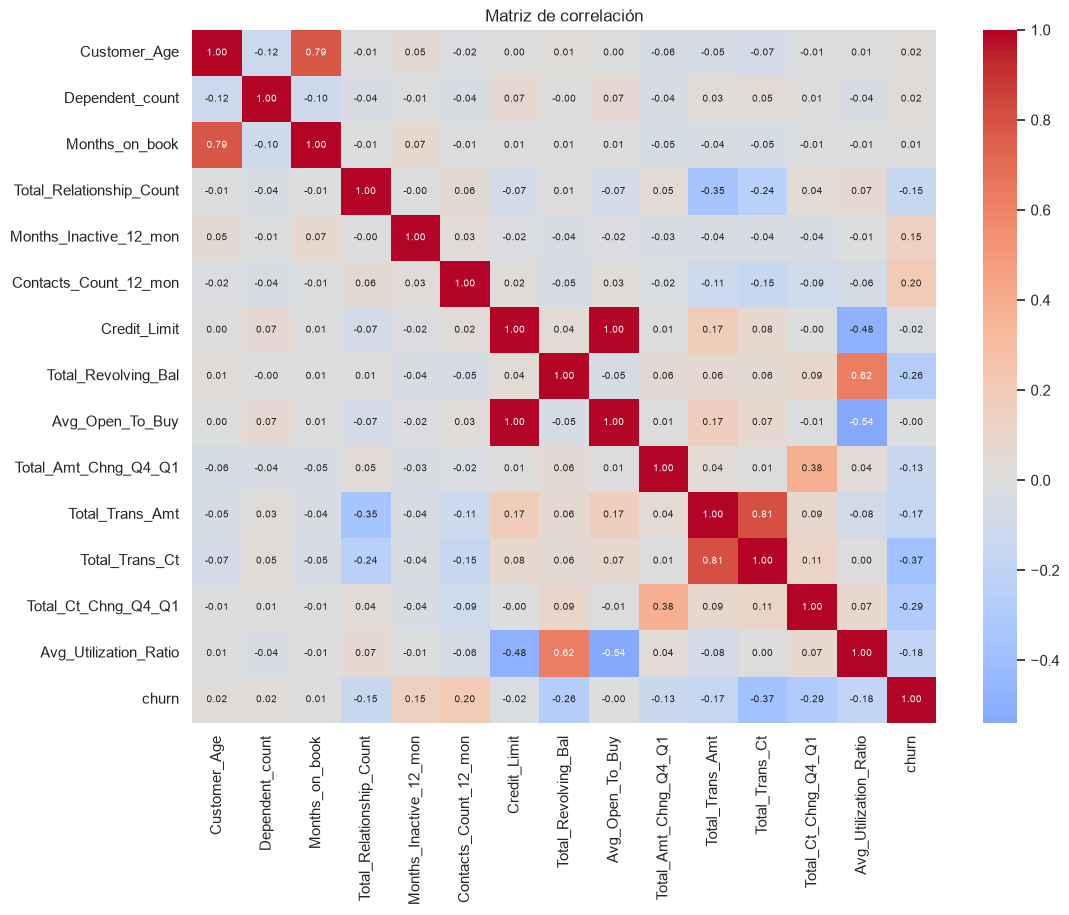


Correlación con el abandono:
Total_Trans_Ct             -0.371
Total_Ct_Chng_Q4_Q1        -0.290
Total_Revolving_Bal        -0.263
Contacts_Count_12_mon       0.204
Avg_Utilization_Ratio      -0.178
Total_Trans_Amt            -0.169
Months_Inactive_12_mon      0.152
Total_Relationship_Count   -0.150
Total_Amt_Chng_Q4_Q1       -0.131
Credit_Limit               -0.024
Dependent_count             0.019
Customer_Age                0.018
Months_on_book              0.014
Avg_Open_To_Buy            -0.000
Name: churn, dtype: float64


In [19]:
corr = df[num_cols + ["churn"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Matriz de correlación")
plt.show()

print("\nCorrelación con el abandono:")
print(corr["churn"].drop("churn").sort_values(key=abs, ascending=False).round(3))

variables numéricas según el abandono

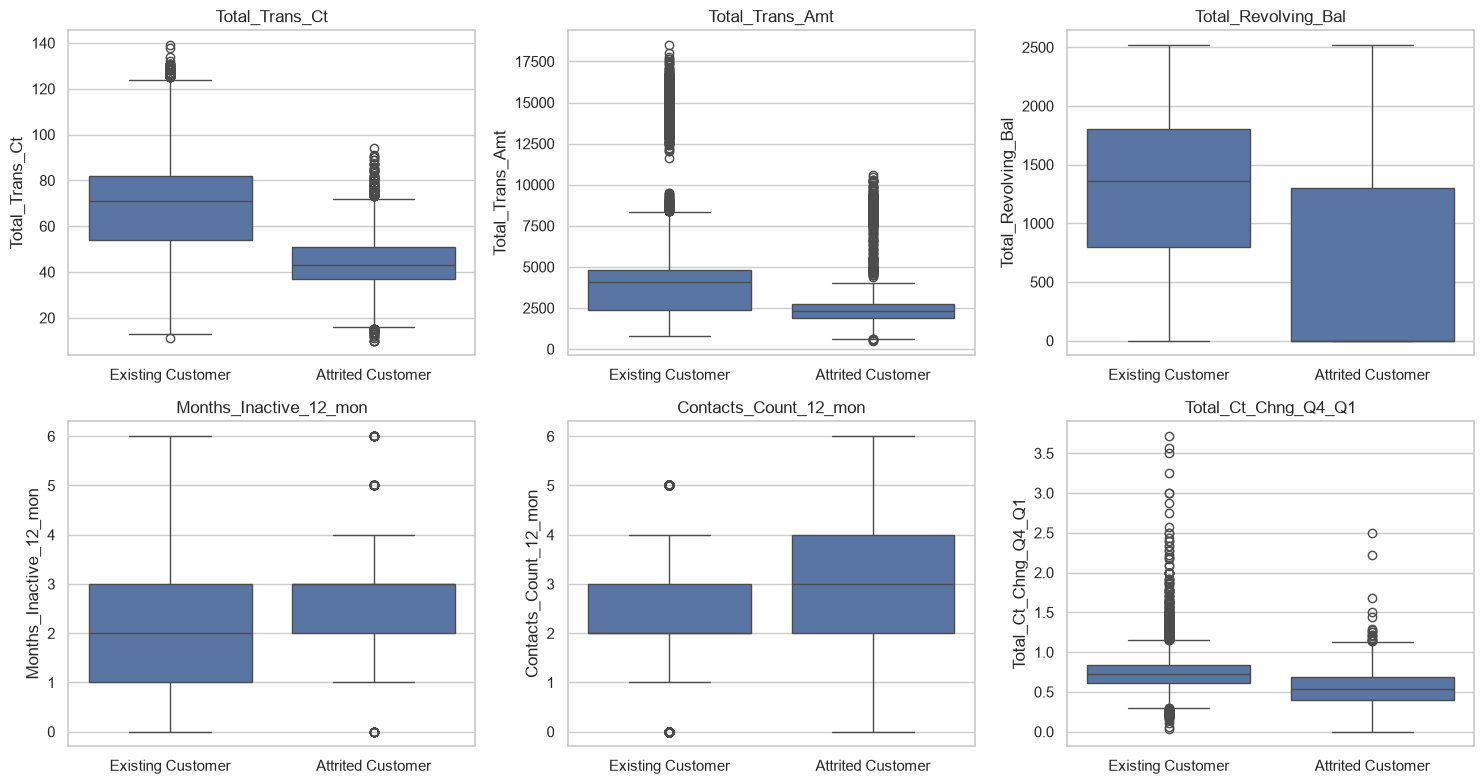

In [20]:
vars_clave = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal",
              "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Total_Ct_Chng_Q4_Q1"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), vars_clave):
    sns.boxplot(data=df, x="Attrition_Flag", y=col, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout()
plt.show()

Decisiones y hallazgos 5.3

| Tema | Decisión propuesta | Justificación |
|---|---|---|
| Nulos | No imputar | La tabla de valores nulos muestra 0 en todas las columnas. |
| `Unknown` | Mantenerlo como categoría propia | No es un nulo técnico y su tasa de abandono puede ser informativa. |
| Outliers | No eliminarlos | Pueden representar clientes reales con límites altos o muchas transacciones. Eliminarlos podría descartar casos relevantes; en modelos lineales se pueden controlar con escalamiento robusto. |
| Codificación | One-Hot para variables nominales (`Gender`, `Marital_Status`, `Education_Level`) y ordinal para `Income_Category` y `Card_Category` | La codificación ordinal conserva el orden natural cuando existe. |
| Escalamiento | Aplicar `StandardScaler` o `RobustScaler` solo a modelos sensibles a la escala, como regresión logística, KNN y SVM | Los modelos basados en árboles no suelen requerir escalamiento. |
| Desbalance | Usar `stratify=y`, `class_weight="balanced"` y métricas como recall, F1 y PR-AUC | La clase de abandono representa cerca del 16 %; la accuracy puede ser engañosa porque un modelo que siempre prediga “se queda” acertaría alrededor del 84 %. |
| Redundancia | Quitar `Avg_Open_To_Buy` y revisar `Avg_Utilization_Ratio` | `Avg_Open_To_Buy` es prácticamente igual a `Credit_Limit - Total_Revolving_Bal`; conviene revisar también la relación de `Avg_Utilization_Ratio` con otras variables. |

#### **5.4 Formulación de X e y**

definir y y X

In [21]:
y = df["churn"]

# Variables que NO entran al modelo
excluir = {
    "CLIENTNUM":       "identificador, sin valor predictivo",
    "Attrition_Flag":  "es el objetivo en texto (leakage directo)",
    "churn":           "es el objetivo codificado (leakage directo)",
    "Avg_Open_To_Buy": "redundante: Credit_Limit - Total_Revolving_Bal",
}

X = df.drop(columns=list(excluir))

print("X:", X.shape, "| y:", y.shape)
print("Clase positiva (abandono):", y.mean().round(4))
pd.DataFrame.from_dict(excluir, orient="index", columns=["motivo"])

X: (10127, 18) | y: (10127,)
Clase positiva (abandono): 0.1607


,motivo
CLIENTNUM,"identificador, sin valor predictivo"
Attrition_Flag,es el objetivo en texto (leakage directo)
churn,es el objetivo codificado (leakage directo)
Avg_Open_To_Buy,redundante: Credit_Limit - Total_Revolving_Bal


separar tipos de variables (las usaremos en el Pipeline)

In [23]:
cols_ordinales = ["Card_Category"]
orden_tarjeta = [["Blue", "Silver", "Gold", "Platinum"]]

cols_nominales = ["Gender", "Education_Level", "Marital_Status", "Income_Category"]

cols_numericas = X.select_dtypes(include="number").columns.tolist()

print("Numéricas :", cols_numericas)
print("Nominales :", cols_nominales)
print("Ordinales :", cols_ordinales)
assert set(cols_numericas + cols_nominales + cols_ordinales) == set(X.columns)

Numéricas : ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Nominales : ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category']
Ordinales : ['Card_Category']


revisión de multicolinealidad (VIF)

In [24]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xn = X[cols_numericas].assign(const=1)
vif = pd.Series(
    [variance_inflation_factor(Xn.values, i) for i in range(len(cols_numericas))],
    index=cols_numericas, name="VIF"
).sort_values(ascending=False)
vif.round(2)

Total_Trans_Amt            3.260
Total_Trans_Ct             3.020
Avg_Utilization_Ratio      2.900
Customer_Age               2.680
Months_on_book             2.660
Total_Revolving_Bal        2.230
Credit_Limit               1.760
Total_Ct_Chng_Q4_Q1        1.210
Total_Amt_Chng_Q4_Q1       1.190
Total_Relationship_Count   1.160
Contacts_Count_12_mon      1.040
Dependent_count            1.030
Months_Inactive_12_mon     1.010
Name: VIF, dtype: float64

#### **5.5 División y estrategia de validación**

división train/test estratificada

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

comparacion = pd.DataFrame({
    "completo": y.value_counts(normalize=True),
    "train":    y_train.value_counts(normalize=True),
    "test":     y_test.value_counts(normalize=True),
}).round(4)
print(comparacion)
print("\nAbandonos en train:", y_train.sum(), "| en test:", y_test.sum())

Train: (8101, 18) | Test: (2026, 18)
       completo  train  test
churn                       
0         0.839  0.839 0.840
1         0.161  0.161 0.160

Abandonos en train: 1302 | en test: 325


validación cruzada estratificada sobre entrenamiento

In [26]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy":  "accuracy",
    "precision": "precision",
    "recall":    "recall",
    "f1":        "f1",
    "roc_auc":   "roc_auc",
    "pr_auc":    "average_precision",
}

Hallazgos 5.5 
- 80/20: con 10.127 registros, el 20 % deja unos 2.026 clientes en test. Eso incluye unos 325 abandonos, suficientes para estimar recall y precision de forma estable. El 80 % restante da datos de sobra para entrenar y validar.
- stratify=y: mantiene la proporción de abandono (~16 %) en train y test. Sin esto, el test podría quedar con una clase minoritaria distinta a la real.
- Validación cruzada estratificada de 5 folds, solo sobre train: sirve para comparar modelos y ajustar hiperparámetros. Cada fold conserva la proporción de clases.
- Test reservado: no se toca hasta la evaluación final (5.7/5.8), para no tomar decisiones de desarrollo con él.
- Métricas: accuracy sola engaña con un 84 % de clase mayoritaria. Seguiremos F1, recall, ROC-AUC y PR-AUC. El recall importa especialmente porque el costo de no detectar a un cliente que se va suele ser mayor que el de contactar a uno que se iba a quedar.

#### **5.6 Entrenamiento y comparación**

imports

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate

preprocesadores

In [28]:
def crear_preprocesador(escalar: bool):
    """Escalar solo para modelos sensibles a la escala (lineales)."""
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", cols_numericas),
        ("nom", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                              sparse_output=False), cols_nominales),
        ("ord", OrdinalEncoder(categories=orden_tarjeta), cols_ordinales),
    ])

modelos a comparar

In [29]:
modelos = {
    "Baseline (clase mayoritaria)": Pipeline([
        ("prep", crear_preprocesador(False)),
        ("clf", DummyClassifier(strategy="most_frequent")),
    ]),
    "Regresión logística": Pipeline([
        ("prep", crear_preprocesador(True)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", crear_preprocesador(False)),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    "Gradient Boosting (Hist)": Pipeline([
        ("prep", crear_preprocesador(False)),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced",
                                               random_state=RANDOM_STATE)),
    ]),
}

validación cruzada sobre TRAIN

In [30]:
resultados = {}
for nombre, pipe in modelos.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, return_train_score=False)
    resultados[nombre] = {m: (cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std())
                          for m in scoring}
    resultados[nombre]["tiempo_fit_s"] = (cv_res["fit_time"].mean(), cv_res["fit_time"].std())
    print(f"OK: {nombre}")

tabla_cv = pd.DataFrame({
    nombre: {m: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in met.items()}
    for nombre, met in resultados.items()
}).T
tabla_cv

OK: Baseline (clase mayoritaria)
OK: Regresión logística
OK: Random Forest
OK: Gradient Boosting (Hist)


,accuracy,precision,recall,f1,roc_auc,pr_auc,tiempo_fit_s
Baseline (clase mayoritaria),0.839 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.161 ± 0.000,0.055 ± 0.002
Regresión logística,0.849 ± 0.007,0.519 ± 0.014,0.847 ± 0.017,0.644 ± 0.012,0.926 ± 0.007,0.749 ± 0.019,0.066 ± 0.003
Random Forest,0.950 ± 0.006,0.928 ± 0.020,0.747 ± 0.022,0.828 ± 0.021,0.988 ± 0.002,0.942 ± 0.013,1.190 ± 0.034
Gradient Boosting (Hist),0.970 ± 0.007,0.892 ± 0.029,0.927 ± 0.017,0.909 ± 0.021,0.993 ± 0.002,0.969 ± 0.008,0.720 ± 0.058


gráfico comparativo

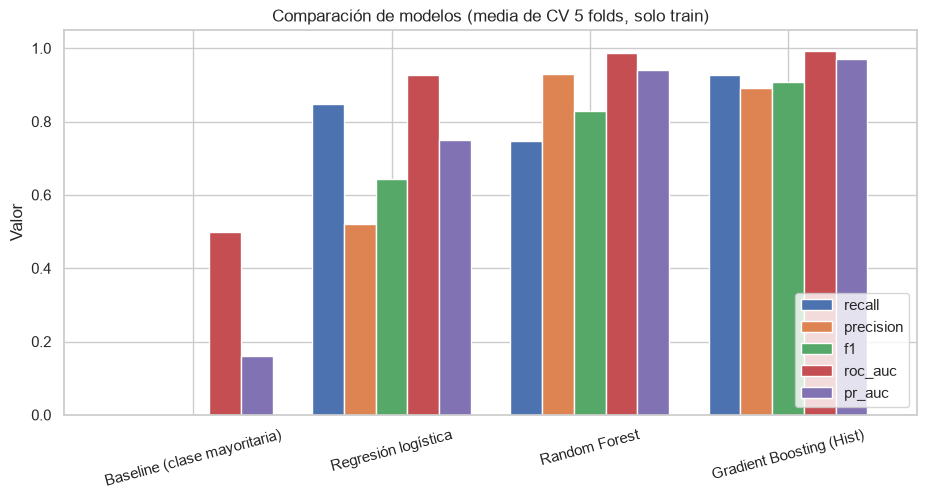

In [31]:
medias = pd.DataFrame({n: {m: v[0] for m, v in met.items() if m != "tiempo_fit_s"}
                       for n, met in resultados.items()}).T

medias[["recall", "precision", "f1", "roc_auc", "pr_auc"]].plot(
    kind="bar", figsize=(11, 5), width=0.8)
plt.title("Comparación de modelos (media de CV 5 folds, solo train)")
plt.ylabel("Valor"); plt.ylim(0, 1.05); plt.xticks(rotation=15)
plt.legend(loc="lower right"); plt.show()

#### **5.7 Evaluación e interpretación**

 Modelo | Familia | Justificación | Hiperparámetros relevantes |
|---|---|---|---|
| Baseline | Regla trivial | Piso de referencia: confirma que los modelos superan la predicción constante de “se queda” (aprox. 84 % de accuracy y 0 de recall). | `strategy` |
| Regresión logística | Modelo lineal | Es rápida e interpretable mediante sus coeficientes, y sirve como punto de comparación. | `C`, `class_weight`, `penalty` |
| Random Forest | Ensamble de árboles (bagging) | Captura relaciones no lineales e interacciones; además, es robusto ante valores atípicos. | `n_estimators`, `max_depth`, `min_samples_leaf`, `class_weight` |
| Gradient Boosting | Ensamble de árboles (boosting) | Suele ofrecer un rendimiento sólido en datos tabulares. | `learning_rate`, `max_iter`, `max_depth`, `l2_regularization` |

| Modelo | Lectura |
|---|---|
| **Baseline** | Accuracy de 0,839 y **recall de 0**: nunca detecta abandonos. Confirma que la accuracy sola no es adecuada para este problema. |
| **Regresión logística** | **Recall alto (0,847)**, pero precision de 0,519: identifica muchos abandonos, aunque genera numerosas falsas alarmas. Es una referencia interpretable. |
| **Random Forest** | **Precision alta (0,928)**, pero recall de 0,747: se le escapa aproximadamente uno de cada cuatro abandonos. |
| **Gradient Boosting** | Mejor F1 (0,909), recall (0,927), ROC-AUC (0,993) y PR-AUC (0,969). Presenta poca variación entre folds y un tiempo de ajuste medio de aproximadamente 0,7 s. |

Candidato: Gradient Boosting. Además, la PR-AUC de 0,969 frente a la línea base de 0,161 es la métrica más informativa aquí, porque no depende de la clase mayoritaria.

#### **5.8 Selección y ajuste**

búsqueda de hiperparámetros

In [33]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

pipe_hgb = modelos["Gradient Boosting (Hist)"]

param_dist = {
    "clf__learning_rate":      loguniform(0.02, 0.3),
    "clf__max_iter":           randint(100, 500),
    "clf__max_leaf_nodes":     randint(8, 64),
    "clf__min_samples_leaf":   randint(10, 60),
    "clf__l2_regularization":  loguniform(1e-3, 10),
}

busqueda = RandomizedSearchCV(
    pipe_hgb, param_distributions=param_dist,
    n_iter=30, scoring=scoring, refit="f1",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)
busqueda.fit(X_train, y_train)

print("Mejores parámetros:")
for k, v in busqueda.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nF1 (CV) mejor config: {busqueda.best_score_:.3f}")

cv_df = pd.DataFrame(busqueda.cv_results_)
cols = ["mean_test_f1", "mean_test_recall", "mean_test_precision",
        "mean_test_pr_auc", "std_test_f1"]
display(cv_df.sort_values("mean_test_f1", ascending=False)[cols].head(5).round(3))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Mejores parámetros:
  clf__l2_regularization: 0.03148911647956861
  clf__learning_rate: 0.262516606324193
  clf__max_iter: 206
  clf__max_leaf_nodes: 15
  clf__min_samples_leaf: 30

F1 (CV) mejor config: 0.917


,mean_test_f1,mean_test_recall,mean_test_precision,mean_test_pr_auc,std_test_f1
0,0.917,0.921,0.914,0.971,0.014
27,0.917,0.922,0.912,0.971,0.016
23,0.916,0.921,0.912,0.971,0.010
4,0.915,0.916,0.916,0.971,0.012
9,0.915,0.912,0.918,0.971,0.011


comparar configuración base vs. ajustada (en CV)

In [34]:
base = resultados["Gradient Boosting (Hist)"]
print("Base     -> F1: {:.3f} | Recall: {:.3f} | PR-AUC: {:.3f}".format(
    base["f1"][0], base["recall"][0], base["pr_auc"][0]))
i = busqueda.best_index_
print("Ajustado -> F1: {:.3f} | Recall: {:.3f} | PR-AUC: {:.3f}".format(
    cv_df.loc[i, "mean_test_f1"], cv_df.loc[i, "mean_test_recall"],
    cv_df.loc[i, "mean_test_pr_auc"]))

modelo_final = busqueda.best_estimator_

Base     -> F1: 0.909 | Recall: 0.927 | PR-AUC: 0.969
Ajustado -> F1: 0.917 | Recall: 0.921 | PR-AUC: 0.971


umbral de decisión (también solo con train)

Umbral que maximiza F1 en CV: 0.570 (F1=0.918)


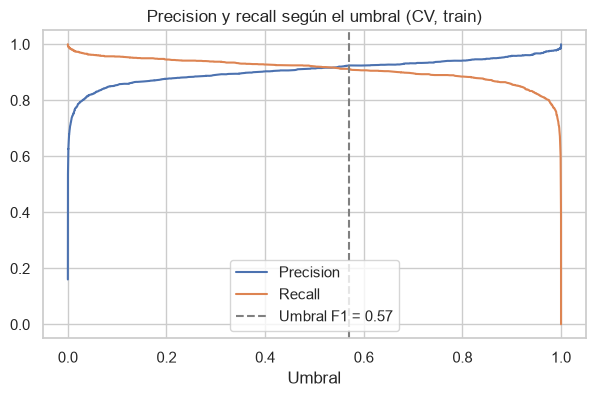

In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

proba_cv = cross_val_predict(modelo_final, X_train, y_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, umbrales = precision_recall_curve(y_train, proba_cv)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
umbral_f1 = umbrales[f1s.argmax()]
print(f"Umbral que maximiza F1 en CV: {umbral_f1:.3f} (F1={f1s.max():.3f})")

plt.figure(figsize=(7, 4))
plt.plot(umbrales, prec[:-1], label="Precision")
plt.plot(umbrales, rec[:-1], label="Recall")
plt.axvline(umbral_f1, color="gray", ls="--", label=f"Umbral F1 = {umbral_f1:.2f}")
plt.xlabel("Umbral"); plt.legend(); plt.title("Precision y recall según el umbral (CV, train)")
plt.show()

Evaluación final en Test (una sola vez)

In [36]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay)

UMBRAL = 0.5     # o umbral_f1, según lo que decidas y justifiques
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL).astype(int)

metricas_test = {
    "accuracy":  accuracy_score(y_test, pred_test),
    "precision": precision_score(y_test, pred_test),
    "recall":    recall_score(y_test, pred_test),
    "f1":        f1_score(y_test, pred_test),
    "roc_auc":   roc_auc_score(y_test, proba_test),
    "pr_auc":    average_precision_score(y_test, proba_test),
}
print(pd.Series(metricas_test).round(3))
print("\n", classification_report(y_test, pred_test,
      target_names=["Se queda", "Abandona"]))

accuracy    0.971
precision   0.921
recall      0.895
f1          0.908
roc_auc     0.993
pr_auc      0.969
dtype: float64

               precision    recall  f1-score   support

    Se queda       0.98      0.99      0.98      1701
    Abandona       0.92      0.90      0.91       325

    accuracy                           0.97      2026
   macro avg       0.95      0.94      0.95      2026
weighted avg       0.97      0.97      0.97      2026



matriz de confusión y curvas

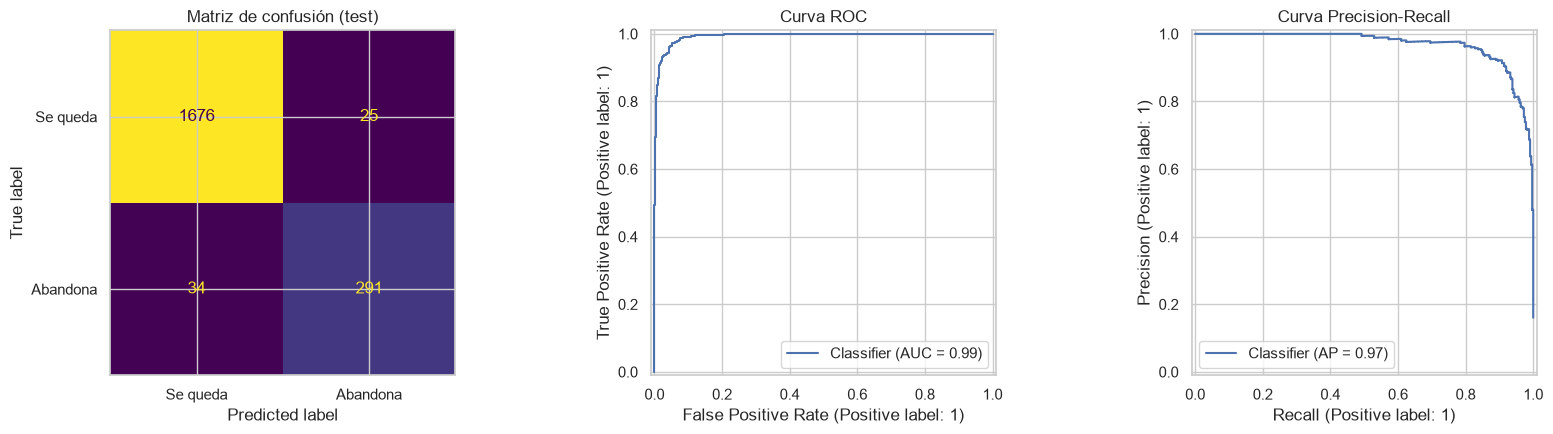

Verdaderos negativos: 1676 | Falsos positivos: 25
Falsos negativos: 34  | Verdaderos positivos: 291


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Se queda", "Abandona"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de confusión (test)")

RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1])
axes[1].set_title("Curva ROC")

PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2])
axes[2].set_title("Curva Precision-Recall")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"Verdaderos negativos: {tn} | Falsos positivos: {fp}")
print(f"Falsos negativos: {fn}  | Verdaderos positivos: {tp}")

importancia de variables (interpretación)

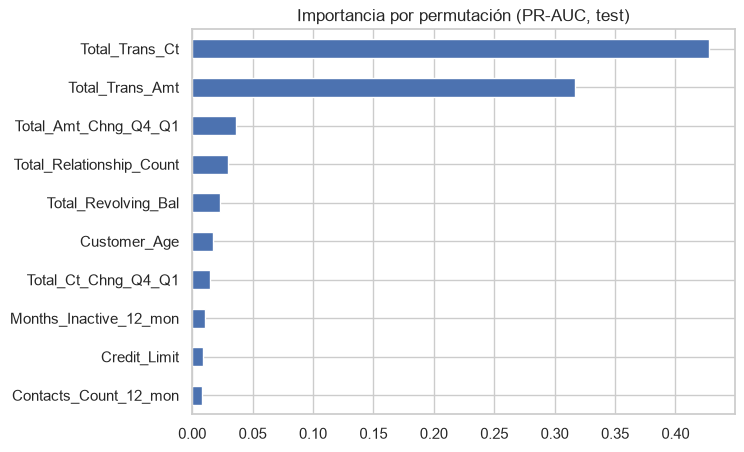

In [38]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

imp.tail(10).plot(kind="barh", figsize=(7, 5))
plt.title("Importancia por permutación (PR-AUC, test)")
plt.show()

Hallazgos modelo aplicado

Ajuste de hiperparámetros

- El F1 en CV pasó de 0,909 a 0,917 y la PR-AUC de 0,969 a 0,971. La mejora es pequeña, y las 5 mejores configuraciones están entre 0,915 y 0,917, así que el modelo es estable frente a los hiperparámetros. Dilo así en el informe: el ajuste confirma una configuración robusta, no un salto de rendimiento.
- Parámetros finales: learning_rate=0,263, max_iter=206, max_leaf_nodes=15, min_samples_leaf=30, l2_regularization=0,031. Árboles pequeños con regularización, buena señal contra el sobreajuste.

Evaluación en test

- F1 de 0,908 en test frente a 0,917 en CV. La diferencia es menor que la desviación entre folds (0,014), así que no hay sobreajuste y las métricas de CV eran una estimación honesta.
- Matriz de confusión: de 325 clientes que abandonan, el modelo detecta 291 (recall 0,895) y se le escapan 34. De los 316 que marca como “abandona”, 25 eran falsas alarmas (precision 0,921). Solo 25 de 1.701 clientes fieles (1,5 %) son contactados sin necesidad.
- PR-AUC de 0,969 frente a la línea base de 0,161, y ROC-AUC de 0,993.
Lectura de negocio: se puede abordar a casi 9 de cada 10 clientes en riesgo con muy pocas falsas alarmas.

### **5.9 Registro del modelo en MLflow**

configuración de MLflow

In [39]:
# !pip install mlflow
import mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from pathlib import Path

BASE_MLFLOW = Path("../05_Evidencias/evidencias_MLflow").resolve()
BASE_MLFLOW.mkdir(parents=True, exist_ok=True)

TRACKING_URI  = f"sqlite:///{(BASE_MLFLOW / 'mlflow.db').as_posix()}"
ARTIFACTS_URI = (BASE_MLFLOW / "artifacts").as_uri()
mlflow.set_tracking_uri(TRACKING_URI)

NOMBRE_EXPERIMENTO = "churn_tarjetas_credito"
NOMBRE_MODELO      = "churn_tarjetas_credito_hgb"

if mlflow.get_experiment_by_name(NOMBRE_EXPERIMENTO) is None:
    mlflow.create_experiment(NOMBRE_EXPERIMENTO, artifact_location=ARTIFACTS_URI)
mlflow.set_experiment(NOMBRE_EXPERIMENTO)

print("Tracking URI:", TRACKING_URI)

2026/11/19 13:08:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 13:08:47 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:///C:/Users/ASUS/OneDrive/Escritorio/Proyecto Final Multivariado/05_Evidencias/evidencias_MLflow/mlflow.db


preparar métricas y figuras

In [40]:
UMBRAL = 0.5   # decisión final, justificada arriba

i = busqueda.best_index_
metricas_cv = {f"cv_{m}": float(cv_df.loc[i, f"mean_test_{m}"]) for m in scoring}
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

fig_cm, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Se queda", "Abandona"]).plot(ax=ax, colorbar=False)
ax.set_title("Matriz de confusión (test)")

fig_roc, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax)
ax.set_title("Curva ROC (test)")

fig_pr, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax)
ax.set_title("Curva Precision-Recall (test)")

fig_imp, ax = plt.subplots(figsize=(7, 5))
imp.tail(10).plot(kind="barh", ax=ax)
ax.set_title("Importancia por permutación (PR-AUC, test)")
fig_imp.tight_layout()
plt.close("all")

ejecución y registro (run)

In [43]:
with mlflow.start_run(run_name="hgb_ajustado_final") as run:
    mlflow.set_tags({
        "proyecto": "Proyecto final minería de datos",
        "dataset": "BankChurners (churn tarjetas de crédito)",
        "tarea": "clasificación binaria",
        "clase_positiva": "Attrited Customer (churn=1)",
    })

    # Parámetros: hiperparámetros del modelo y configuración del experimento
    mlflow.log_params({k.replace("clf__", ""): v for k, v in busqueda.best_params_.items()})
    mlflow.log_params({
        "algoritmo": "HistGradientBoostingClassifier",
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
        "test_size": 0.20,
        "cv_folds": 5,
        "umbral_decision": UMBRAL,
        "n_train": len(X_train),
        "n_test": len(X_test),
        "n_variables": X_train.shape[1],
    })

    # Métricas: validación cruzada (train) y evaluación final (test)
    mlflow.log_metrics(metricas_cv)
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in metricas_test.items()})
    mlflow.log_metrics({"test_tn": float(tn), "test_fp": float(fp),
                        "test_fn": float(fn), "test_tp": float(tp)})

    # Artefactos: figuras y metadatos de entrada
    mlflow.log_figure(fig_cm,  "figuras/matriz_confusion.png")
    mlflow.log_figure(fig_roc, "figuras/curva_roc.png")
    mlflow.log_figure(fig_pr,  "figuras/curva_pr.png")
    mlflow.log_figure(fig_imp, "figuras/importancia_variables.png")
    mlflow.log_dict({
        "numericas": cols_numericas,
        "nominales": cols_nominales,
        "ordinales": cols_ordinales,
        "excluidas": excluir,
    }, "metadatos/columnas_entrada.json")

    signature = infer_signature(X_train, modelo_final.predict(X_train))
    mlflow.sklearn.log_model(
        sk_model=modelo_final,
        name="modelo",                       # en MLflow 2.x: artifact_path="modelo"
        signature=signature,
        input_example=X_train.head(3),
        registered_model_name=NOMBRE_MODELO,
        skops_trusted_types=[
            "sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor"
        ],
    )

    RUN_ID = run.info.run_id

print("Run ID:", RUN_ID)

2026/11/19 13:15:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'churn_tarjetas_credito_hgb'.

Run ID: ec4dbc999a7840a3abc8aeebac315705



Created version '1' of model 'churn_tarjetas_credito_hgb'.


version y alias

In [44]:
client = MlflowClient()
versiones = client.search_model_versions(f"name='{NOMBRE_MODELO}'")
ultima = max(versiones, key=lambda v: int(v.version))

client.set_registered_model_alias(NOMBRE_MODELO, "champion", ultima.version)
client.update_model_version(
    NOMBRE_MODELO, ultima.version,
    description="HistGradientBoosting ajustado por RandomizedSearchCV (5-fold). "
                "Pipeline con preprocesamiento incluido. Umbral de decisión 0.5."
)
print(f"Modelo: {NOMBRE_MODELO} | versión: {ultima.version} | alias: champion")

Modelo: churn_tarjetas_credito_hgb | versión: 1 | alias: champion


verificar que se recupera idéntico

In [45]:
modelo_cargado = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO}@champion")
proba_check = modelo_cargado.predict_proba(X_test)[:, 1]
print("Predicciones idénticas al modelo en memoria:", np.allclose(proba_check, proba_test))

print("\nPara abrir la interfaz, ejecuta esto en una terminal:")
print(f'mlflow ui --backend-store-uri "{TRACKING_URI}"')

Predicciones idénticas al modelo en memoria: True

Para abrir la interfaz, ejecuta esto en una terminal:
mlflow ui --backend-store-uri "sqlite:///C:/Users/ASUS/OneDrive/Escritorio/Proyecto Final Multivariado/05_Evidencias/evidencias_MLflow/mlflow.db"
